<a href="https://colab.research.google.com/github/Santhosh5578/ReadMe/blob/main/Copy_of_Learning_Pulse_ML_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Learning Pulse: An Explainable Early-Warning System for Student Academic Risk
**Machine Learning Project | Reproducible Notebook**

## Research question
Can student background, study habits, and school-support variables identify students at risk of failing before final grades are known—and can the model provide calibrated, actionable, and fair risk estimates?

## Important scope
This notebook uses the UCI Student Performance dataset (Math course; `student-mat.csv`). It compares:
- **Early-warning scenario:** excludes prior course grades (`G1`, `G2`) to avoid relying on grades that may not yet exist.
- **Mid-course scenario:** includes `G1` and `G2` to measure the benefit of interim grades.

The target is **academic risk**: final grade `G3 < 10` on the dataset's 0–20 scale. This is a research prototype, not a system for making consequential decisions about students. Predictions should support human-led assistance, never punishment or labeling.


## 1. Setup and reproducibility

In [ ]:
import sys, warnings, urllib.request, zipfile, io, os, random
warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, average_precision_score, brier_score_loss,
                             precision_recall_curve, roc_curve, f1_score, recall_score,
                             precision_score, accuracy_score)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, VotingClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.inspection import permutation_importance

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__, "| pandas:", pd.__version__)

Python: 3.13.18
NumPy: 2.4.6 | pandas: 2.2.3


## 2. Load dataset

In [ ]:
import urllib.request
import zipfile
import io
import pandas as pd

url = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"

try:
    # Download outer ZIP
    response = urllib.request.urlopen(url, timeout=30)
    outer_zip = zipfile.ZipFile(io.BytesIO(response.read()))

    # Find the inner ZIP
    inner_name = next(
        name for name in outer_zip.namelist()
        if name.lower().endswith("student.zip")
    )

    inner_zip = zipfile.ZipFile(
        io.BytesIO(outer_zip.read(inner_name))
    )

    # Load mathematics dataset
    csv_name = next(
        name for name in inner_zip.namelist()
        if name.lower().endswith("student-mat.csv")
    )

    with inner_zip.open(csv_name) as f:
        df = pd.read_csv(f, sep=";")

except Exception as e:
    print("UCI download failed:", repr(e))
    print("Trying backup dataset...")

    backup_url = (
        "https://raw.githubusercontent.com/"
        "selva86/datasets/master/student-mat.csv"
    )
    df = pd.read_csv(backup_url, sep=";")

print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


## 3. Define the prediction task and inspect data

In [ ]:
print("df exists:", "df" in globals())

if "df" in globals():
    print(df.shape)
    display(df.head())

df exists: False


In [ ]:
TARGET = "at_risk"
df[TARGET] = (df["G3"] < 10).astype(int)
print("At-risk prevalence:", round(df[TARGET].mean(), 3))
print(df[TARGET].value_counts().rename(index={0:"Not at risk", 1:"At risk"}))
display(df.describe(include="all").T)

At-risk prevalence: 0.329
at_risk
Not at risk    265
At risk        130
Name: count, dtype: int64


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
school,395,2,GP,349,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,395,2,F,208,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,395.0,NaN,NaN,NaN,16.696203,1.276043,15.0,16.0,17.0,18.0,22.0
address,395,2,U,307,NaN,NaN,NaN,NaN,NaN,NaN,NaN
famsize,395,2,GT3,281,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Pstatus,395,2,T,354,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Medu,395.0,NaN,NaN,NaN,2.749367,1.094735,0.0,2.0,3.0,4.0,4.0
Fedu,395.0,NaN,NaN,NaN,2.521519,1.088201,0.0,2.0,2.0,3.0,4.0
Mjob,395,5,other,141,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fjob,395,5,other,217,NaN,NaN,NaN,NaN,NaN,NaN,NaN


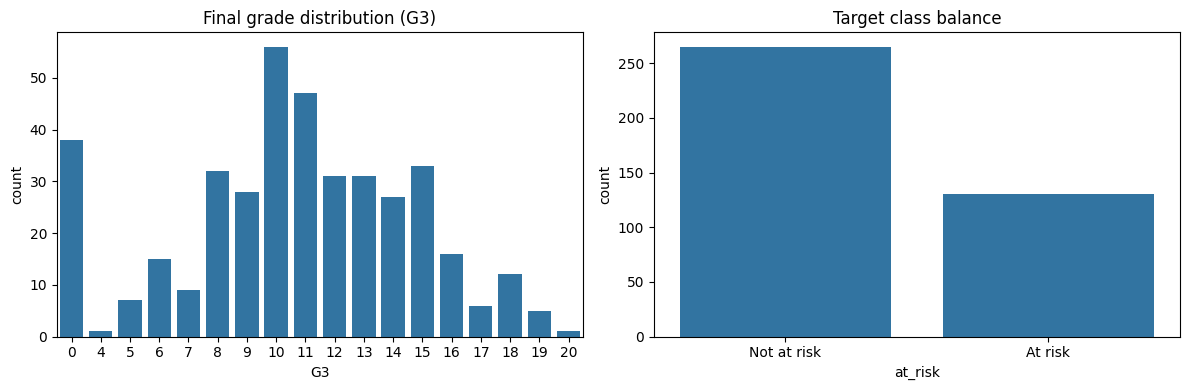

Missing cells: 0
Duplicate rows: 0


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x="G3", ax=axes[0])
axes[0].set_title("Final grade distribution (G3)")
sns.countplot(data=df, x=TARGET, ax=axes[1])
axes[1].set_title("Target class balance")
axes[1].set_xticklabels(["Not at risk", "At risk"])
plt.tight_layout()
plt.show()

# Missingness and duplicate checks
print("Missing cells:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

## 4. Leakage-aware feature sets
`G3` is excluded from all predictors because it defines the target. The early-warning model also excludes `G1` and `G2`; the mid-course model includes them. We split before fitting preprocessing to prevent train/test leakage.

In [ ]:
y = df[TARGET]
drop_cols = ["G3", TARGET]
early_features = [c for c in df.columns if c not in drop_cols + ["G1", "G2"]]
mid_features = [c for c in df.columns if c not in drop_cols]

X_early = df[early_features].copy()
X_mid = df[mid_features].copy()

X_train_e, X_test_e, y_train, y_test = train_test_split(
    X_early, y, test_size=0.20, random_state=SEED, stratify=y)
X_train_m, X_test_m, _, _ = train_test_split(
    X_mid, y, test_size=0.20, random_state=SEED, stratify=y)

numeric_features = X_early.select_dtypes(include=np.number).columns.tolist()
categorical_features = [c for c in X_early.columns if c not in numeric_features]

def make_preprocessor(feature_columns):
    nums = [c for c in feature_columns if pd.api.types.is_numeric_dtype(df[c])]
    cats = [c for c in feature_columns if c not in nums]
    numeric_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")),
                             ("scaler", StandardScaler())])
    categorical_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                                 ("onehot", OneHotEncoder(handle_unknown="ignore"))])
    return ColumnTransformer([("num", numeric_pipe, nums),
                             ("cat", categorical_pipe, cats)])

print("Early features:", len(early_features), "| Mid-course features:", len(mid_features))

Early features: 30 | Mid-course features: 32


## 5. Baseline and candidate models

In [ ]:
def model_pipeline(model, features):
    return Pipeline([("prep", make_preprocessor(features)), ("model", model)])

models = {
    "Logistic Regression": LogisticRegression(max_iter=3000, class_weight="balanced", random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=500, min_samples_leaf=2,
                                            class_weight="balanced", random_state=SEED, n_jobs=-1)
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {"roc_auc":"roc_auc", "average_precision":"average_precision",
           "recall":"recall", "f1":"f1", "balanced_accuracy":"balanced_accuracy"}

cv_rows=[]
for name, model in models.items():
    pipe=model_pipeline(model, early_features)
    scores=cross_validate(pipe, X_train_e, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    cv_rows.append({"Model":name, **{m: scores["test_"+m].mean() for m in scoring}})
cv_results=pd.DataFrame(cv_rows).sort_values("average_precision", ascending=False)
display(cv_results)

,Model,roc_auc,average_precision,recall,f1,balanced_accuracy
1,Random Forest,0.653648,0.531968,0.309048,0.386096,0.583870
0,Logistic Regression,0.631113,0.489453,0.539524,0.477952,0.595177


## 6. Tune the strongest candidate using training data only

In [ ]:
rf_pipe = model_pipeline(RandomForestClassifier(class_weight="balanced", random_state=SEED, n_jobs=-1),
                        early_features)
param_grid = {
    "model__n_estimators":[300, 500],
    "model__max_depth":[None, 8, 14],
    "model__min_samples_leaf":[1, 2, 4],
    "model__max_features":["sqrt", 0.7]
}
search = GridSearchCV(rf_pipe, param_grid, scoring="average_precision", cv=cv,
                      n_jobs=-1, refit=True, verbose=1)
search.fit(X_train_e, y_train)
best_early=search.best_estimator_
print("Best CV average precision:", round(search.best_score_, 4))
print("Best parameters:", search.best_params_)

Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best CV average precision: 0.5541
Best parameters: {'model__max_depth': 8, 'model__max_features': 0.7, 'model__min_samples_leaf': 4, 'model__n_estimators': 500}


## 7. Test-set evaluation and threshold selection

OOF F1-selected threshold: 0.281
              precision    recall  f1-score   support

 Not at risk       0.95      0.34      0.50        53
     At risk       0.42      0.96      0.58        26

    accuracy                           0.54        79
   macro avg       0.68      0.65      0.54        79
weighted avg       0.77      0.54      0.53        79

ROC-AUC: 0.754
PR-AUC / Average precision: 0.628
Brier score: 0.1852
Recall: 0.9615
Precision: 0.4167


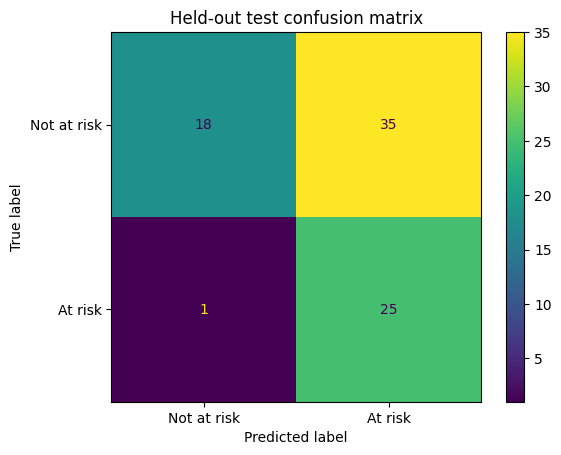

In [ ]:
# Threshold is selected on out-of-fold training predictions, not the test set.
from sklearn.model_selection import cross_val_predict
oof_prob = cross_val_predict(best_early, X_train_e, y_train, cv=cv,
                             method="predict_proba", n_jobs=-1)[:,1]
p, r, thresholds = precision_recall_curve(y_train, oof_prob)
f1_values = 2*p[:-1]*r[:-1]/(p[:-1]+r[:-1]+1e-12)
best_threshold = float(thresholds[np.argmax(f1_values)])
print("OOF F1-selected threshold:", round(best_threshold, 3))

test_prob = best_early.predict_proba(X_test_e)[:,1]
test_pred = (test_prob >= best_threshold).astype(int)
print(classification_report(y_test, test_pred, target_names=["Not at risk","At risk"], zero_division=0))
print("ROC-AUC:", round(roc_auc_score(y_test, test_prob), 4))
print("PR-AUC / Average precision:", round(average_precision_score(y_test, test_prob), 4))
print("Brier score:", round(brier_score_loss(y_test, test_prob), 4))
print("Recall:", round(recall_score(y_test, test_pred, zero_division=0), 4))
print("Precision:", round(precision_score(y_test, test_pred, zero_division=0), 4))
ConfusionMatrixDisplay.from_predictions(y_test, test_pred, display_labels=["Not at risk","At risk"])
plt.title("Held-out test confusion matrix")
plt.show()

## 8. Compare early-warning and mid-course scenarios

In [ ]:
mid_pipe = model_pipeline(RandomForestClassifier(**{
    k.replace("model__",""):v for k,v in search.best_params_.items()
}, class_weight="balanced", random_state=SEED, n_jobs=-1), mid_features)
mid_pipe.fit(X_train_m, y_train)
mid_prob=mid_pipe.predict_proba(X_test_m)[:,1]
comparison=pd.DataFrame([
    {"Scenario":"Early warning (no G1/G2)", "ROC-AUC":roc_auc_score(y_test,test_prob),
     "Average precision":average_precision_score(y_test,test_prob), "Brier":brier_score_loss(y_test,test_prob)},
    {"Scenario":"Mid-course (includes G1/G2)", "ROC-AUC":roc_auc_score(y_test,mid_prob),
     "Average precision":average_precision_score(y_test,mid_prob), "Brier":brier_score_loss(y_test,mid_prob)}
])
display(comparison)

,Scenario,ROC-AUC,Average precision,Brier
0,Early warning (no G1/G2),0.753991,0.627996,0.185233
1,Mid-course (includes G1/G2),0.963716,0.927851,0.070762


## 9. Explainability with permutation importance

,Mean AP decrease
failures,0.224539
age,0.021443
absences,0.021373
goout,0.019899
schoolsup,0.017952
guardian,0.009662
nursery,0.007283
studytime,0.007147
school,0.005541
health,0.004903


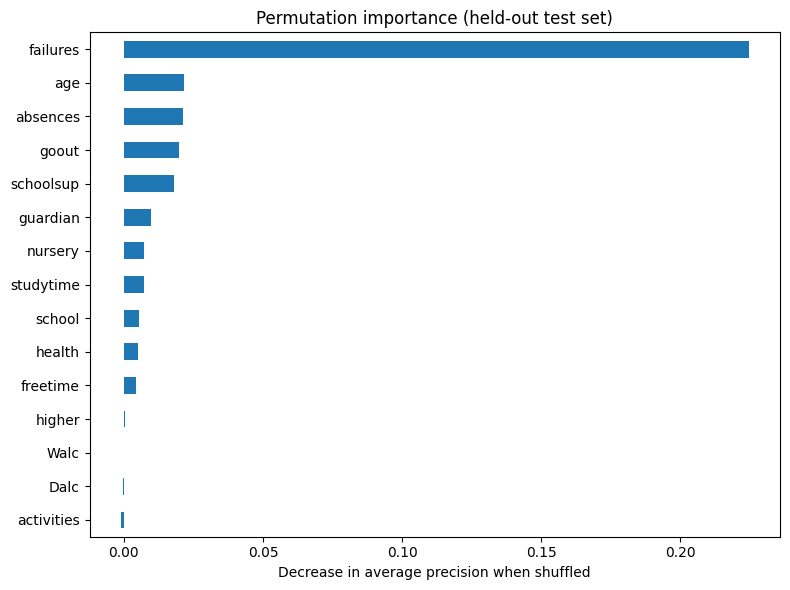

In [ ]:
perm = permutation_importance(best_early, X_test_e, y_test, scoring="average_precision",
                              n_repeats=20, random_state=SEED, n_jobs=-1)
importance=pd.Series(perm.importances_mean, index=early_features).sort_values(ascending=False)
display(importance.head(15).to_frame("Mean AP decrease"))
importance.head(15).sort_values().plot(kind="barh", figsize=(8,6))
plt.title("Permutation importance (held-out test set)")
plt.xlabel("Decrease in average precision when shuffled")
plt.tight_layout()
plt.show()

## 10. Calibration and decision-support analysis

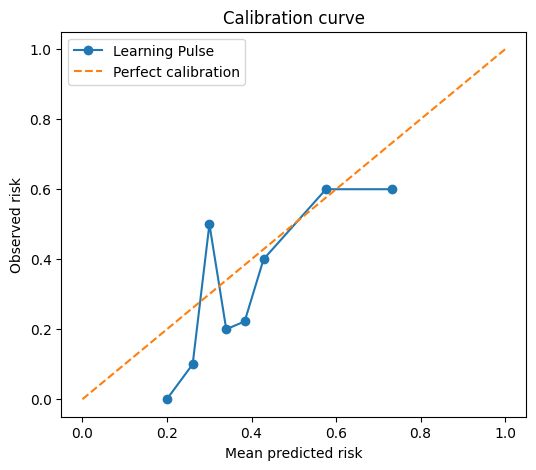

,Threshold,Flagged,Recall,Precision
0,0.200,74,1.000000,0.351351
1,0.300,55,0.884615,0.418182
2,0.400,31,0.615385,0.516129
3,0.500,18,0.461538,0.666667
4,0.281,60,0.961538,0.416667


In [ ]:
prob_true, prob_pred = calibration_curve(y_test, test_prob, n_bins=8, strategy="quantile")
plt.figure(figsize=(6,5))
plt.plot(prob_pred, prob_true, marker="o", label="Learning Pulse")
plt.plot([0,1],[0,1],"--", label="Perfect calibration")
plt.xlabel("Mean predicted risk"); plt.ylabel("Observed risk")
plt.title("Calibration curve"); plt.legend(); plt.show()

# Decision threshold trade-off: estimate workload vs captured at-risk students.
rows=[]
for t in [0.20,0.30,0.40,0.50,best_threshold]:
    pred=(test_prob>=t).astype(int)
    rows.append({"Threshold":round(float(t),3),"Flagged":int(pred.sum()),
                 "Recall":recall_score(y_test,pred,zero_division=0),
                 "Precision":precision_score(y_test,pred,zero_division=0)})
display(pd.DataFrame(rows).drop_duplicates())

## 11. Advanced technique: probability calibration
Calibration can improve the interpretability of risk scores. Fit calibration on training data only, then evaluate once on the held-out test set. Compare Brier scores; do not assume calibration improves performance.

In [ ]:
calibrated = CalibratedClassifierCV(best_early, method="sigmoid", cv=5)
calibrated.fit(X_train_e, y_train)
cal_prob=calibrated.predict_proba(X_test_e)[:,1]
print("Uncalibrated Brier:", round(brier_score_loss(y_test,test_prob),4))
print("Calibrated Brier:", round(brier_score_loss(y_test,cal_prob),4))
print("Uncalibrated ROC-AUC:", round(roc_auc_score(y_test,test_prob),4))
print("Calibrated ROC-AUC:", round(roc_auc_score(y_test,cal_prob),4))

Uncalibrated Brier: 0.1852
Calibrated Brier: 0.1903
Uncalibrated ROC-AUC: 0.754
Calibrated ROC-AUC: 0.7293


## 12. Limitations, ethics, and deployment recommendation
- The dataset is historical, relatively small, and from Portuguese secondary schools; external validity is limited.
- Risk is a proxy based on `G3 < 10`; it does not measure ability, effort, or potential.
- Associations are not causal explanations. Feature importance is predictive, not causal.
- Group-level performance should be audited before any real deployment; sensitive or proxy variables may encode inequity.
- Use predictions only to offer supportive resources (tutoring, check-ins, counseling), with student/teacher context and human review.
- Do not publish identifiable student-level predictions.

## 13. Final conclusion (complete after running)
Report the actual held-out metrics, strongest predictors, early-vs-midcourse comparison, calibration result, and limitations. Do not invent results: copy values from the executed notebook.
